In [37]:
import pandas as pd
import numpy as np
import uproot
import matplotlib.pyplot as plt

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [5]:
df_truth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.root', "MatchedTree"),\
              'pt>5 and b!=-9 and w<1')

In [6]:
df_truth

,pt,b,w,y1,y2,phi1,phi2,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs
0,6.909035,-1,1.335866e-10,-0.566667,-0.581373,0.254736,0.123353,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
2,5.072170,1,1.335866e-10,-0.282474,-0.409867,5.993405,0.018299,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
3,7.017721,1,1.335866e-10,0.213610,-0.212909,2.084065,2.228717,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
4,10.088763,-1,1.335866e-10,0.446627,0.397990,5.020298,5.315151,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
5,15.125875,-1,1.335866e-10,0.316357,0.707073,0.230565,6.271781,-9.0,-9,1.335866e-10,-9.0,-9.0,-9.0,-9.0,-9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21485688,7.442665,1,3.372111e-10,-0.116277,-0.174830,3.373234,3.460523,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
21485689,5.589589,-1,3.372111e-10,-0.138695,0.013598,5.879950,6.135971,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
21485691,12.328792,-1,3.372111e-10,-0.236462,0.165022,4.458089,4.457092,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0
21485692,8.193869,-1,3.372111e-10,-0.508361,-0.585699,4.988478,4.940525,-9.0,-9,-9.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0


In [7]:
df_corrected = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/rc_corrected.csv', low_memory=False,\
                           usecols=['pt','b','w','r'])
new_w = df_corrected['w']*df_corrected['r']
df_corrected['w'] = new_w
df_corrected = df_corrected.drop('r', axis=1)
df_corrected

,pt,b,w
0,15.950633,-1,1.284744e-10
1,11.627170,-1,1.284744e-10
2,18.259376,1,1.452983e-10
3,17.829490,-1,1.279928e-10
4,16.916830,-1,1.284744e-10
...,...,...,...
2630092,15.216081,1,3.667749e-10
2630093,12.440178,-1,3.243066e-10
2630094,13.415522,-1,3.243066e-10
2630095,15.122849,-1,3.243066e-10


# $p_{T}^{truth}$->$p_{T}^{det}$
## find reweight = $b_{corrected}/b_{truth}$ with all truth

In [8]:
df_truth_pt_array = [ df_truth[(df_truth.pt>5) & (df_truth.pt<10)],\
                         df_truth[(df_truth.pt>10) & (df_truth.pt<15)],\
                         df_truth[(df_truth.pt>15) & (df_truth.pt<20)],\
                       df_truth[(df_truth.pt>20) & (df_truth.pt<25)],\
                       df_truth[(df_truth.pt>25) & (df_truth.pt<30)],\
                       df_truth[(df_truth.pt>30) & (df_truth.pt<40)],\
                       df_truth[(df_truth.pt>40) & (df_truth.pt<60)]  ]

In [9]:
df_corrected_pt_array = [ df_corrected[(df_corrected.pt>5) & (df_corrected.pt<10)],\
                         df_corrected[(df_corrected.pt>10) & (df_corrected.pt<15)],\
                         df_corrected[(df_corrected.pt>15) & (df_corrected.pt<20)],\
                       df_corrected[(df_corrected.pt>20) & (df_corrected.pt<25)],\
                       df_corrected[(df_corrected.pt>25) & (df_corrected.pt<30)],\
                       df_corrected[(df_corrected.pt>30) & (df_corrected.pt<40)],\
                       df_corrected[(df_corrected.pt>40) & (df_corrected.pt<60)]  ]

In [10]:
b_truth_array = []
b_truth_err_array = []
for i in range(0,len(df_truth_pt_array)):
    print("pt bin:", i)
    df_truth_pt = df_truth_pt_array[i]
    y_truth,yerr_truth,x = calc_hist(df_truth_pt['b'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_truth_pt['w'])
    p = y_truth[0]/sum(y_truth)
    q = y_truth[1]/sum(y_truth)
    print("b_truth:", np.array([p,q]))
    b_truth_array.append(np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_truth_pt['b'], bins=[range_low, range_high], weights=df_truth_pt['w'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    print("b_truth_err:", np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    b_truth_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

pt bin: 0
b_truth: [0.6499358 0.3500642]
b_truth_err: [0.00281634 0.00281634]
pt bin: 1
b_truth: [0.68706091 0.31293909]
b_truth_err: [0.00143061 0.00143061]
pt bin: 2
b_truth: [0.68986275 0.31013725]
b_truth_err: [0.00076885 0.00076885]
pt bin: 3
b_truth: [0.68946251 0.31053749]
b_truth_err: [0.00077303 0.00077303]
pt bin: 4
b_truth: [0.68974903 0.31025097]
b_truth_err: [0.00101762 0.00101762]
pt bin: 5
b_truth: [0.68781733 0.31218267]
b_truth_err: [0.00128593 0.00128593]
pt bin: 6
b_truth: [0.68543662 0.31456338]
b_truth_err: [0.00176402 0.00176402]


In [11]:
b_corrected_array = []
b_corrected_err_array = []
for i in range(0,len(df_corrected_pt_array)):
    print("pt bin:", i)
    df_corrected_pt = df_corrected_pt_array[i]
    y_corrected,yerr_corrected,x = calc_hist(df_corrected_pt['b'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_corrected_pt['w'])
    p = y_corrected[0]/sum(y_corrected)
    q = y_corrected[1]/sum(y_corrected)
    print("b_corrected:", np.array([p,q]))
    b_corrected_array.append(np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_corrected_pt['b'], bins=[range_low, range_high], weights=df_corrected_pt['w'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    print("b_corrected_err:", np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    b_corrected_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

pt bin: 0
b_corrected: [0.77614706 0.22385294]
b_corrected_err: [0.07364088 0.07364088]
pt bin: 1
b_corrected: [0.68371334 0.31628666]
b_corrected_err: [0.00459083 0.00459083]
pt bin: 2
b_corrected: [0.66832713 0.33167287]
b_corrected_err: [0.00144034 0.00144034]
pt bin: 3
b_corrected: [0.6594456 0.3405544]
b_corrected_err: [0.00113503 0.00113503]
pt bin: 4
b_corrected: [0.65958554 0.34041446]
b_corrected_err: [0.0014112 0.0014112]
pt bin: 5
b_corrected: [0.65751916 0.34248084]
b_corrected_err: [0.00175252 0.00175252]
pt bin: 6
b_corrected: [0.66905375 0.33094625]
b_corrected_err: [0.00257798 0.00257798]


In [12]:
reweight_array = []
reweight_err_array = []
for i in range(0,7):
    numerator = b_corrected_array[i]/sum(b_corrected_array[i])
    denominator = b_truth_array[i]/sum(b_truth_array[i])
    numerator_err = b_corrected_err_array[i]/sum(b_corrected_array[i])
#     print(numerator_err/numerator)
    denominator_err = b_truth_err_array[i]/sum(b_truth_array[i])
#     print(denominator_err/denominator)
    reweight = numerator/denominator
    reweight_err = reweight*np.sqrt((numerator_err/numerator)**2+(denominator_err/denominator)**2)
    reweight_array.append(reweight)
    reweight_err_array.append(reweight_err)

In [13]:
reweight_array

[array([1.19419035, 0.63946253]),
 array([0.99512771, 1.01069717]),
 array([0.96878275, 1.069439  ]),
 array([0.95646333, 1.09666113]),
 array([0.95626889, 1.09722287]),
 array([0.95595027, 1.0970527 ]),
 array([0.97609864, 1.05208129])]

In [131]:
reweight_err_array

[array([0.11342296, 0.21042683]),
 array([0.00699574, 0.01538045]),
 array([0.00235053, 0.00534768]),
 array([0.00196473, 0.00456201]),
 array([0.00248524, 0.00580013]),
 array([0.00311227, 0.00720661]),
 array([0.00452285, 0.01009821])]

## reweight matched jets

In [14]:
df_match_temp = df_truth[(df_truth.pts>15) & (df_truth.bs!=-9)]
distance1 = []
distance2 = []
for i in range(0,df_match_temp.shape[0]):
    phi1small = min(df_match_temp.iloc[i]['phi1'], df_match_temp.iloc[i]['phi1s'])
    phi1large = max(df_match_temp.iloc[i]['phi1'], df_match_temp.iloc[i]['phi1s'])
    phi2small = min(df_match_temp.iloc[i]['phi2'], df_match_temp.iloc[i]['phi2s'])
    phi2large = max(df_match_temp.iloc[i]['phi2'], df_match_temp.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_match_temp.iloc[i]['phi1'], df_match_temp.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_match_temp.iloc[i]['y1']-df_match_temp.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_match_temp.iloc[i]['y2']-df_match_temp.iloc[i]['y2s'])**2))
df_match_temp['distance1'] = distance1
df_match_temp['distance2'] = distance2

/tmp/ipykernel_114258/206874416.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match_temp['distance1'] = distance1
/tmp/ipykernel_114258/206874416.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match_temp['distance2'] = distance2


In [15]:
df_match = df_match_temp[(df_match_temp.distance1<0.02) & (df_match_temp.distance2<0.02)]

In [16]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pt'] > 5 and df_match.iloc[i]['pt'] < 10):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pt'] > 10 and df_match.iloc[i]['pt'] < 15):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pt'] > 15 and df_match.iloc[i]['pt'] < 20):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pt'] > 20 and df_match.iloc[i]['pt'] < 25):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pt'] > 25 and df_match.iloc[i]['pt'] < 30):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    elif (df_match.iloc[i]['pt'] > 30 and df_match.iloc[i]['pt'] < 40):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[5][0])
        else:
            r.append(reweight_array[5][1])
    elif (df_match.iloc[i]['pt'] > 40 and df_match.iloc[i]['pt'] < 60):
        if (df_match.iloc[i]['b']==-1):
            r.append(reweight_array[6][0])
        else:
            r.append(reweight_array[6][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pt'])
df_match['r'] = r

anomaly reco pT: 60.567712130820134
anomaly reco pT: 60.7941224644189
anomaly reco pT: 62.403341889167436
anomaly reco pT: 60.36687216873327
anomaly reco pT: 60.941686257418844
anomaly reco pT: 61.7074497713591
anomaly reco pT: 65.01496909621885
anomaly reco pT: 61.629124704957086
anomaly reco pT: 60.47001325301055
anomaly reco pT: 61.954798365591316
anomaly reco pT: 60.60638456510946
anomaly reco pT: 60.94761598093837
anomaly reco pT: 68.26857999555766
anomaly reco pT: 63.33921093788539
anomaly reco pT: 61.742135380079844
anomaly reco pT: 64.08431782492184
anomaly reco pT: 60.01356991125786
anomaly reco pT: 66.41741460330122
anomaly reco pT: 61.20159846542131
anomaly reco pT: 63.010684539877694
anomaly reco pT: 61.79041119497007
anomaly reco pT: 60.25992578429341
anomaly reco pT: 61.17793476099247
anomaly reco pT: 65.50570786655221
anomaly reco pT: 63.364679775665614
anomaly reco pT: 63.30429344916698
anomaly reco pT: 63.526443680223615
anomaly reco pT: 60.416438497775005
anomaly reco

anomaly reco pT: 62.612859169183615
anomaly reco pT: 61.82180056234742
anomaly reco pT: 60.68598297456504
anomaly reco pT: 61.77213633037819
anomaly reco pT: 64.39971744845906
anomaly reco pT: 67.17596211291227
anomaly reco pT: 66.2905919203012
anomaly reco pT: 63.3283361077684
anomaly reco pT: 62.15598585478937
anomaly reco pT: 61.53896510735924
anomaly reco pT: 60.54269416931335
anomaly reco pT: 62.521653719834745
anomaly reco pT: 64.96496376165739
anomaly reco pT: 63.98868595278952
anomaly reco pT: 60.30697725587951
anomaly reco pT: 60.748794958392565
anomaly reco pT: 61.479158097283744
anomaly reco pT: 64.09759485499406
anomaly reco pT: 62.25229846306093
anomaly reco pT: 62.45234986133161
anomaly reco pT: 63.5936537330926
anomaly reco pT: 63.30760284792229
anomaly reco pT: 60.553007676115264
anomaly reco pT: 60.39605739121278
anomaly reco pT: 60.7949076124863
anomaly reco pT: 61.810676405360155
anomaly reco pT: 62.87930411486019
anomaly reco pT: 62.511487165382114
anomaly reco pT: 

anomaly reco pT: 62.4496549023784
anomaly reco pT: 66.62598624257801
anomaly reco pT: 62.7793710331367
anomaly reco pT: 61.80830987760232
anomaly reco pT: 60.720005294960586
anomaly reco pT: 61.22937006363944
anomaly reco pT: 61.53960821138565
anomaly reco pT: 61.79815113316272
anomaly reco pT: 65.96076077334972
anomaly reco pT: 60.029714105056904
anomaly reco pT: 64.16664035069326
anomaly reco pT: 63.88981005195045
anomaly reco pT: 63.52130885207319
anomaly reco pT: 60.34684602875454
anomaly reco pT: 60.31359941465955
anomaly reco pT: 60.46083253084333
anomaly reco pT: 62.19185278331817
anomaly reco pT: 60.485740579560066
anomaly reco pT: 60.879755877146565
anomaly reco pT: 65.78410744172555
anomaly reco pT: 62.47376795459435
anomaly reco pT: 60.23990880586309
anomaly reco pT: 64.66249266318268
anomaly reco pT: 62.60199904953769
anomaly reco pT: 60.98194635653181
anomaly reco pT: 62.327108415316005
anomaly reco pT: 60.16032610429924
anomaly reco pT: 64.87345962626323
anomaly reco pT: 

anomaly reco pT: 61.74430811518353
anomaly reco pT: 62.724922129413294
anomaly reco pT: 61.59893140590396
anomaly reco pT: 61.27551803036842
anomaly reco pT: 66.57819659979815
anomaly reco pT: 64.63322567036855
anomaly reco pT: 61.03614253427804
anomaly reco pT: 61.11477377938164
anomaly reco pT: 63.2022596227834
anomaly reco pT: 62.313268781043384
anomaly reco pT: 60.11516230241749
anomaly reco pT: 72.05519505725348
anomaly reco pT: 65.07136099738915
anomaly reco pT: 60.90169329437605
anomaly reco pT: 61.05927441651605
anomaly reco pT: 61.01330111549689
anomaly reco pT: 61.57676893810256
anomaly reco pT: 65.72298886458186
anomaly reco pT: 60.599016075568485
anomaly reco pT: 65.27565525481711
anomaly reco pT: 61.898834574728355
anomaly reco pT: 61.939548087509586
anomaly reco pT: 61.17335846173493
anomaly reco pT: 60.22187508307094
anomaly reco pT: 61.14716611982245
anomaly reco pT: 63.48267546669504
anomaly reco pT: 67.93664548441873
anomaly reco pT: 60.494058968220585
anomaly reco pT

anomaly reco pT: 65.33156243319829
anomaly reco pT: 61.4362569468168
anomaly reco pT: 62.15412356055891
anomaly reco pT: 62.30337316199472
anomaly reco pT: 63.46630518201442
anomaly reco pT: 63.93962901089351
anomaly reco pT: 62.11672624149806
anomaly reco pT: 62.771861195299444
anomaly reco pT: 61.86528197656084
anomaly reco pT: 71.36321511881697
anomaly reco pT: 67.39362758657914
anomaly reco pT: 67.3814991096839
anomaly reco pT: 60.47055093761422
anomaly reco pT: 63.88839573035396
anomaly reco pT: 61.84365871276571
anomaly reco pT: 60.84753460576698
anomaly reco pT: 60.150908900495125
anomaly reco pT: 60.81164179459097
anomaly reco pT: 60.38904315497921
anomaly reco pT: 60.77371837559213
anomaly reco pT: 63.65920505348842
anomaly reco pT: 60.060589249730334
anomaly reco pT: 60.61414570058586
anomaly reco pT: 61.189098375107804
anomaly reco pT: 68.48383332864648
anomaly reco pT: 65.08304495107079
anomaly reco pT: 63.414706107224156
anomaly reco pT: 62.576622503430556
anomaly reco pT:

anomaly reco pT: 60.492945987313135
anomaly reco pT: 61.89567895741682
anomaly reco pT: 60.57105178042476
anomaly reco pT: 60.51161654327195
anomaly reco pT: 64.50893739089459
anomaly reco pT: 64.0319672455971
anomaly reco pT: 63.11747425011589
anomaly reco pT: 60.00254441955931
anomaly reco pT: 60.237863163180016
anomaly reco pT: 60.11561321842007
anomaly reco pT: 63.51270034436747
anomaly reco pT: 63.281675868130655
anomaly reco pT: 60.4731407105186
anomaly reco pT: 61.93431167192932
anomaly reco pT: 66.34175499074367
anomaly reco pT: 62.31249399825083
anomaly reco pT: 64.8851591228337
anomaly reco pT: 62.459696460847944
anomaly reco pT: 60.47625600146676
anomaly reco pT: 61.675392253253165
anomaly reco pT: 62.89314602397908
anomaly reco pT: 61.60195491494475
anomaly reco pT: 63.48961950726903
anomaly reco pT: 67.011157225265
anomaly reco pT: 60.36044269528527
anomaly reco pT: 63.38439843978756
anomaly reco pT: 63.04079348563968
anomaly reco pT: 61.86139039992079
anomaly reco pT: 64.

... (97 outputs left out)

anomaly reco pT: 64.01263306173128
anomaly reco pT: 60.44536428418831
anomaly reco pT: 64.00620764915907
anomaly reco pT: 61.57331908547823
anomaly reco pT: 60.50703593170182
anomaly reco pT: 62.82541924671689
anomaly reco pT: 63.99450505036286
anomaly reco pT: 61.901091298802655
anomaly reco pT: 60.79855605095869
anomaly reco pT: 61.750063705412245
anomaly reco pT: 60.89649243613326
anomaly reco pT: 60.504704888714315
anomaly reco pT: 64.56087358582144
anomaly reco pT: 60.030860518939186
anomaly reco pT: 60.706163605510206
anomaly reco pT: 63.435469377191225
anomaly reco pT: 72.67005282635154
anomaly reco pT: 60.70184012519305
anomaly reco pT: 60.08107951294005
anomaly reco pT: 61.63946229778013
anomaly reco pT: 63.65106946507732
anomaly reco pT: 63.311709102883604
anomaly reco pT: 66.2015295226823
anomaly reco pT: 65.70051227901435
anomaly reco pT: 60.14836136363782
anomaly reco pT: 60.82622750844817
anomaly reco pT: 68.06990269910864
anomaly reco pT: 62.311592987557695
anomaly reco 

anomaly reco pT: 60.618064077034376
anomaly reco pT: 60.44239109845274
anomaly reco pT: 60.32096111348401
anomaly reco pT: 65.20782967774132
anomaly reco pT: 63.239323268616246
anomaly reco pT: 60.01098197217498
anomaly reco pT: 64.05934689840205
anomaly reco pT: 60.46258632314763
anomaly reco pT: 67.21721273653962
anomaly reco pT: 63.3549036734654
anomaly reco pT: 60.26616217083464
anomaly reco pT: 62.44799405362653
anomaly reco pT: 61.239867471293216
anomaly reco pT: 62.24248848331403
anomaly reco pT: 60.105758594841156
anomaly reco pT: 62.24657813064707
anomaly reco pT: 60.62062454603371
anomaly reco pT: 61.20206999274105
anomaly reco pT: 65.56284006704905
anomaly reco pT: 68.41591443373012
anomaly reco pT: 66.43514265369467
anomaly reco pT: 65.85190977074969
anomaly reco pT: 65.41758088011194
anomaly reco pT: 60.77955143969006
anomaly reco pT: 64.13255388456255
anomaly reco pT: 64.3693870736679
anomaly reco pT: 60.26401731904241
anomaly reco pT: 64.53250930469059
anomaly reco pT: 6

anomaly reco pT: 62.185855643482554
anomaly reco pT: 60.08485900760681
anomaly reco pT: 65.25340463283939
anomaly reco pT: 62.472214386040946
anomaly reco pT: 60.71174188522641
anomaly reco pT: 60.503924814019996
anomaly reco pT: 60.562881778820305
anomaly reco pT: 62.84529353204452
anomaly reco pT: 63.724534389704026
anomaly reco pT: 62.04919351686327
anomaly reco pT: 60.29982713166753
anomaly reco pT: 61.53724687013762
anomaly reco pT: 60.479188978473196
anomaly reco pT: 61.77580591198655
anomaly reco pT: 60.23554717184831
anomaly reco pT: 62.19256211644701
anomaly reco pT: 60.589216133630565
anomaly reco pT: 61.2028113577827
anomaly reco pT: 60.46744317447092
anomaly reco pT: 62.60412234999823
anomaly reco pT: 64.02554384121585
anomaly reco pT: 63.121301160237664
anomaly reco pT: 65.98079317867196
anomaly reco pT: 64.69656299480752
anomaly reco pT: 63.41707776132237
anomaly reco pT: 61.77422450149466
anomaly reco pT: 69.44831363679496
anomaly reco pT: 60.30115727299017
anomaly reco 

/tmp/ipykernel_114258/250612844.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r


In [17]:
df_match

,pt,b,w,y1,y2,phi1,phi2,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2,r
288,15.950633,-1,1.335866e-10,-0.231618,-0.182024,2.146205,2.364211,15.322203,-1,1.335866e-10,-0.228193,-0.179157,2.145820,2.362274,0.440774,0.003447,0.003460,0.968783
424,11.627170,-1,1.335866e-10,0.012581,0.064953,1.534992,1.500074,17.218631,-1,1.335866e-10,0.014168,0.065035,1.535264,1.500260,0.394044,0.001610,0.000203,0.995128
669,18.259376,1,1.335866e-10,0.048015,0.197089,3.930451,4.287787,16.581160,1,1.335866e-10,0.047744,0.197269,3.931439,4.286936,0.641544,0.001025,0.000870,1.069439
707,17.829490,-1,1.335866e-10,0.201174,0.230069,3.458130,3.315959,21.092371,-1,1.335866e-10,0.202457,0.230661,3.458050,3.314660,0.172536,0.001286,0.001427,0.968783
757,16.916830,-1,1.335866e-10,0.574970,0.550261,2.704811,2.819210,18.452512,-1,1.335866e-10,0.575996,0.549288,2.704523,2.818100,0.390038,0.001066,0.001476,0.968783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21479313,15.216081,1,3.372111e-10,0.154965,0.269487,1.599096,1.344846,15.637151,1,3.372111e-10,0.154016,0.268211,1.597867,1.344304,0.248716,0.001553,0.001386,1.069439
21479914,12.440178,-1,3.372111e-10,0.111286,-0.031407,3.979175,3.952633,15.281649,-1,3.372111e-10,0.107507,-0.036808,3.979858,3.951718,0.502125,0.003840,0.005478,0.995128
21480861,13.415522,-1,3.372111e-10,0.042592,0.149746,3.166025,3.068481,15.268221,-1,3.372111e-10,0.042417,0.156447,3.165678,3.067195,0.389922,0.000389,0.006824,0.995128
21481999,15.122849,-1,3.372111e-10,-0.458183,-0.343605,3.834345,3.735383,18.864532,-1,3.372111e-10,-0.459918,-0.346789,3.834382,3.736320,0.268977,0.001735,0.003319,0.968783


# combine matched jets and fake jets to get all reco
## bin reweighted matched jets in $p_T^{det}$ and find their $b_{det}$

In [20]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]]

In [72]:
b_match_array = []
b_match_err_array = []
for i in range(0,5):
    print("pts bin:", i)
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['w']*df_match_pts['r'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    p = y_reco[0]/sum(y_reco)
    q = y_reco[1]/sum(y_reco)
    print("b_matched:", np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_match_pts[ob+'s'], bins=[range_low, range_high], weights=df_match_pts['w']*df_match_pts['r'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    b_match_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    print("b_matched_err (PYTHIA stats):", np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

pts bin: 0
b_matched: [0.67829054 0.32170946]
b_matched_err (PYTHIA stats): [0.00150142 0.00150142]
pts bin: 1
b_matched: [0.66754509 0.33245491]
b_matched_err (PYTHIA stats): [0.00131028 0.00131028]
pts bin: 2
b_matched: [0.66651403 0.33348597]
b_matched_err (PYTHIA stats): [0.00172427 0.00172427]
pts bin: 3
b_matched: [0.66959968 0.33040032]
b_matched_err (PYTHIA stats): [0.00214268 0.00214268]
pts bin: 4
b_matched: [0.67775655 0.32224345]
b_matched_err (PYTHIA stats): [0.00428714 0.00428714]


## find error on matched jets $b_{det}$ due to reweighting error

In [77]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p_final = nss/(nss+nos)
    print(p_final)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

In [74]:
binedges = np.array([5, 10, 15, 20, 25, 30, 40, 60])

In [113]:
df_match_cut = applyCut(df_match, '15<pts<20')
df_match_pt_array = [ df_match_cut[(df_match_cut.pt>5) & (df_match_cut.pt<10)],\
                     df_match_cut[(df_match_cut.pt>10) & (df_match_cut.pt<15)],\
                     df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)],\
                       df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)],\
                       df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)],\
                       df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)],\
                       df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)] ]

In [114]:
rc_match_array = []
rc_err_match_array = []
p_match_array = []
for i in range(0, len(df_match_pt_array)):
    # for a given truth pT range, what is its rc
    rc, rc_err, p = getRcAndErr(df_match_pt_array[i], 'b')
    rc_match_array.append(rc)
    rc_err_match_array.append(rc_err)
    p_match_array.append(p)

0.20300422029336704
0.2907518701185631
0.3061291498337681
0.3203455738710449
0.30382652797484655
0.2803289224271848
0.27378034577583865


In [115]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '15<pts<20 and b==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>15) & (df_match_cut.pts<20)]['w'])/sum(df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)]['w']))
prob_array

[0.0020040276193878637,
 0.21659979664383874,
 0.6698854266940505,
 0.10354003282160511,
 0.007108710249592675,
 0.0008423627187255494,
 1.963002486491346e-05]

In [116]:
reweight_array[0][1]*p_match_array[0]*prob_array[0]+reweight_array[1][1]*p_match_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_array[2]*prob_array[2]+reweight_array[3][1]*p_match_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_array[4]*prob_array[4]+reweight_array[5][1]*p_match_array[5]*prob_array[5]+\
reweight_array[6][1]*p_match_array[6]*prob_array[6]

0.32223124658757096

In [110]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '15<pts<20 and b==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>15) & (df_match_cut.pts<20)]['w'])/sum(df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)]['w']))
prob_array

[0.003431582941485362,
 0.23044833232697656,
 0.6622383545327343,
 0.09581148303682407,
 0.00710431868783904,
 0.0009432028882477481,
 2.2710485729834722e-05]

In [111]:
reweight_array[0][0]*(1-p_match_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_array[4])*prob_array[4]+reweight_array[5][0]*(1-p_match_array[5])*prob_array[5]+\
reweight_array[6][0]*(1-p_match_array[6])*prob_array[6]

0.678596775666656

In [117]:
0.32223124658757096/(0.32223124658757096+0.678596775666656)

0.32196465269006913

In [122]:
rc_rwerr_match_array = []

In [123]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_array[4]*prob_array[4])**2+\
        (reweight_err_array[5][1]*p_match_array[5]*prob_array[5])**2+\
        (reweight_err_array[6][1]*p_match_array[6]*prob_array[6])**2)
print(p_err)
rc_rwerr_match_array.append(2*p_err)

0.0014735158164767231


In [124]:
df_match_cut = applyCut(df_match, '20<pts<25')
df_match_pt_array = [ df_match_cut[(df_match_cut.pt>5) & (df_match_cut.pt<10)],\
                     df_match_cut[(df_match_cut.pt>10) & (df_match_cut.pt<15)],\
                     df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)],\
                       df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)],\
                       df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)],\
                       df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)],\
                       df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)] ]

In [125]:
rc_match_array = []
rc_err_match_array = []
p_match_array = []
for i in range(0, len(df_match_pt_array)):
    # for a given truth pT range, what is its rc
    rc, rc_err, p = getRcAndErr(df_match_pt_array[i], 'b')
    rc_match_array.append(rc)
    rc_err_match_array.append(rc_err)
    p_match_array.append(p)

0.2222221796236258
0.2398564052947854
0.2912704052040865
0.30877709292058486
0.32306840818934224
0.31271401504697766
0.3045125218783327


In [126]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '20<pts<25 and b==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>20) & (df_match_cut.pts<25)]['w'])/sum(df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)]['w']))
prob_array

[0.00012917866078906174,
 0.007240888828512011,
 0.2573459810640081,
 0.6111268355857993,
 0.11263686253169666,
 0.011306410302004194,
 0.00021371920608669994]

In [127]:
reweight_array[0][1]*p_match_array[0]*prob_array[0]+reweight_array[1][1]*p_match_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_array[2]*prob_array[2]+reweight_array[3][1]*p_match_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_array[4]*prob_array[4]+reweight_array[5][1]*p_match_array[5]*prob_array[5]+\
reweight_array[6][1]*p_match_array[6]*prob_array[6]

0.3327526315789856

In [97]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '20<pts<25 and b==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>20) & (df_match_cut.pts<25)]['w'])/sum(df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)]['w']))
prob_array

[0.00019838861208493867,
 0.010069177790563153,
 0.2747637331792237,
 0.6002915260598302,
 0.10355919016561285,
 0.010903669868139206,
 0.00021418325841427745]

In [98]:
reweight_array[0][0]*(1-p_match_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_array[4])*prob_array[4]+reweight_array[5][0]*(1-p_match_array[5])*prob_array[5]+\
reweight_array[6][0]*(1-p_match_array[6])*prob_array[6]

0.6676715643339783

In [128]:
0.3327526315789856/(0.3327526315789856+0.6676715643339783)

0.3326115391234848

In [129]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_array[4]*prob_array[4])**2+\
        (reweight_err_array[5][1]*p_match_array[5]*prob_array[5])**2+\
        (reweight_err_array[6][1]*p_match_array[6]*prob_array[6])**2)
print(p_err)
rc_rwerr_match_array.append(2*p_err)

0.0009735013793489437


In [133]:
df_match_cut = applyCut(df_match, '25<pts<30')
df_match_pt_array = [ df_match_cut[(df_match_cut.pt>5) & (df_match_cut.pt<10)],\
                     df_match_cut[(df_match_cut.pt>10) & (df_match_cut.pt<15)],\
                     df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)],\
                       df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)],\
                       df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)],\
                       df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)],\
                       df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)] ]

In [134]:
rc_match_array = []
rc_err_match_array = []
p_match_array = []
for i in range(0, len(df_match_pt_array)):
    # for a given truth pT range, what is its rc
    rc, rc_err, p = getRcAndErr(df_match_pt_array[i], 'b')
    rc_match_array.append(rc)
    rc_err_match_array.append(rc_err)
    p_match_array.append(p)

0.4054694430160218
0.3332447674151449
0.24637678785936765
0.2914100819122099
0.30802398627427396
0.3222500085782373
0.3049691359988437


In [135]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '25<pts<30 and b==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>25) & (df_match_cut.pts<30)]['w'])/sum(df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)]['w']))
prob_array

[6.51774021140301e-05,
 0.0005955957774768845,
 0.017639218976762582,
 0.2825597879485222,
 0.5626986224642672,
 0.13442167715443226,
 0.002019017691565404]

In [136]:
reweight_array[0][1]*p_match_array[0]*prob_array[0]+reweight_array[1][1]*p_match_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_array[2]*prob_array[2]+reweight_array[3][1]*p_match_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_array[4]*prob_array[4]+reweight_array[5][1]*p_match_array[5]*prob_array[5]+\
reweight_array[6][1]*p_match_array[6]*prob_array[6]

0.3335101496496809

In [137]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '25<pts<30 and b==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>25) & (df_match_cut.pts<30)]['w'])/sum(df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)]['w']))
prob_array

[4.1664911324651084e-05,
 0.0005195317208811611,
 0.023522918010634657,
 0.2995422703979014,
 0.551111814020967,
 0.12325463452723517,
 0.002006068188343265]

In [138]:
reweight_array[0][0]*(1-p_match_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_array[4])*prob_array[4]+reweight_array[5][0]*(1-p_match_array[5])*prob_array[5]+\
reweight_array[6][0]*(1-p_match_array[6])*prob_array[6]

0.6664562489434172

In [139]:
0.3335101496496809/(0.3335101496496809+0.6664562489434172)

0.333521356436489

In [140]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_array[4]*prob_array[4])**2+\
        (reweight_err_array[5][1]*p_match_array[5]*prob_array[5])**2+\
        (reweight_err_array[6][1]*p_match_array[6]*prob_array[6])**2)
print(p_err)
rc_rwerr_match_array.append(2*p_err)

0.0011004417503930187


In [141]:
df_match_cut = applyCut(df_match, '30<pts<40')
df_match_pt_array = [ df_match_cut[(df_match_cut.pt>5) & (df_match_cut.pt<10)],\
                     df_match_cut[(df_match_cut.pt>10) & (df_match_cut.pt<15)],\
                     df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)],\
                       df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)],\
                       df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)],\
                       df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)],\
                       df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)] ]

In [142]:
rc_match_array = []
rc_err_match_array = []
p_match_array = []
for i in range(0, len(df_match_pt_array)):
    # for a given truth pT range, what is its rc
    rc, rc_err, p = getRcAndErr(df_match_pt_array[i], 'b')
    rc_match_array.append(rc)
    rc_err_match_array.append(rc_err)
    p_match_array.append(p)

0.4910668068944076
0.517785296121349
0.3931576202562966
0.258054206517014
0.2866623691548203
0.30736780684460785
0.32222072908450955


In [143]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '30<pts<40 and b==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>30) & (df_match_cut.pts<40)]['w'])/sum(df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)]['w']))
prob_array

[9.809403663447343e-06,
 0.0007244852331351019,
 0.0025356104408597777,
 0.02855816133618669,
 0.25566409325202083,
 0.6706740917975874,
 0.04181524152094068]

In [144]:
reweight_array[0][1]*p_match_array[0]*prob_array[0]+reweight_array[1][1]*p_match_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_array[2]*prob_array[2]+reweight_array[3][1]*p_match_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_array[4]*prob_array[4]+reweight_array[5][1]*p_match_array[5]*prob_array[5]+\
reweight_array[6][1]*p_match_array[6]*prob_array[6]

0.3302707966374536

In [145]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '30<pts<40 and b==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>30) & (df_match_cut.pts<40)]['w'])/sum(df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)]['w']))
prob_array

[4.377836877489205e-06,
 0.00029054743442974136,
 0.0016853438010561393,
 0.03535804533258582,
 0.27396239772330366,
 0.6508075708246271,
 0.03787618135856405]

In [146]:
reweight_array[0][0]*(1-p_match_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_array[4])*prob_array[4]+reweight_array[5][0]*(1-p_match_array[5])*prob_array[5]+\
reweight_array[6][0]*(1-p_match_array[6])*prob_array[6]

0.6690780031220381

In [147]:
0.3302707966374536/(0.3302707966374536+0.6690780031220381)

0.33048600920613325

In [148]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_array[4]*prob_array[4])**2+\
        (reweight_err_array[5][1]*p_match_array[5]*prob_array[5])**2+\
        (reweight_err_array[6][1]*p_match_array[6]*prob_array[6])**2)
print(p_err)
rc_rwerr_match_array.append(2*p_err)

0.0015174371972266397


In [149]:
df_match_cut = applyCut(df_match, '40<pts<60')
df_match_pt_array = [ df_match_cut[(df_match_cut.pt>5) & (df_match_cut.pt<10)],\
                     df_match_cut[(df_match_cut.pt>10) & (df_match_cut.pt<15)],\
                     df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)],\
                       df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)],\
                       df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)],\
                       df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)],\
                       df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)] ]

In [150]:
rc_match_array = []
rc_err_match_array = []
p_match_array = []
for i in range(0, len(df_match_pt_array)):
    # for a given truth pT range, what is its rc
    rc, rc_err, p = getRcAndErr(df_match_pt_array[i], 'b')
    rc_match_array.append(rc)
    rc_err_match_array.append(rc_err)
    p_match_array.append(p)

0.5
0.0
0.447591554374185
0.08394510122127523
0.13485340950225838
0.288228783309154
0.31369678262470346


In [151]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '40<pts<60 and b==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>40) & (df_match_cut.pts<60)]['w'])/sum(df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)]['w']))
prob_array

[3.0515294108815197e-07,
 0.0,
 0.00010687192211492228,
 0.0011984837439346667,
 0.008253825207040624,
 0.36973361476000755,
 0.6188021928788389]

In [152]:
reweight_array[0][1]*p_match_array[0]*prob_array[0]+reweight_array[1][1]*p_match_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_array[2]*prob_array[2]+reweight_array[3][1]*p_match_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_array[4]*prob_array[4]+reweight_array[5][1]*p_match_array[5]*prob_array[5]+\
reweight_array[6][1]*p_match_array[6]*prob_array[6]

0.3225195074137468

In [153]:
prob_array = []
for i in range(0, 7):
    df_match_cut = applyCut(df_match, '40<pts<60 and b==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pt>binedges[i]) & (df_match_cut.pt<binedges[i+1]) & (df_match_cut.pts>40) & (df_match_cut.pts<60)]['w'])/sum(df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)]['w']))
prob_array

[1.3058408368077648e-07,
 2.170766303939138e-05,
 5.6443603544031214e-05,
 0.005596686467757609,
 0.022659781756458483,
 0.3907191484277664,
 0.5793359784761306]

In [154]:
reweight_array[0][0]*(1-p_match_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_array[4])*prob_array[4]+reweight_array[5][0]*(1-p_match_array[5])*prob_array[5]+\
reweight_array[6][0]*(1-p_match_array[6])*prob_array[6]

0.6776515372467076

In [155]:
0.3225195074137468/(0.3225195074137468+0.6776515372467076)

0.32246435160821735

In [156]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_array[4]*prob_array[4])**2+\
        (reweight_err_array[5][1]*p_match_array[5]*prob_array[5])**2+\
        (reweight_err_array[6][1]*p_match_array[6]*prob_array[6])**2)
print(p_err)
rc_rwerr_match_array.append(2*p_err)

0.0020067315588179167


In [157]:
rc_rwerr_match_array

[0.0029470316329534463,
 0.0019470027586978875,
 0.0022008835007860375,
 0.0030348743944532794,
 0.0040134631176358335]

## bin fake jets in $p_{T}^{det}$ and find their $b_{det}$

In [45]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [46]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]]

In [47]:
b_fake_array = []
b_fake_err_array = []
for i in range(0,5):
    print("pts bin:", i)
    df_fake_pts = df_allfake_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['w'], density=True)
    b_fake_array.append(y_reco/sum(y_reco))
    p = y_reco[0]/sum(y_reco)
    q = y_reco[1]/sum(y_reco)
    print("b_fake:", np.array([p,q]))
    eff_count,eff_count_err,x = calc_hist(df_fake_pts[ob+'s'], bins=[range_low, range_high], weights=df_fake_pts['w'], density=True)
    #print("count, err", eff_count,eff_count_err)
    sqrt_n_over_n = eff_count_err[0]/eff_count[0]
    #print((1/sqrt_n_over_n)**2)
    b_fake_err_array.append(np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))
    print("b_fake_err:", np.array([np.sqrt(p*q)*sqrt_n_over_n, np.sqrt(p*q)*sqrt_n_over_n]))

pts bin: 0
b_fake: [0.61905173 0.38094827]
b_fake_err: [0.00279767 0.00279767]
pts bin: 1
b_fake: [0.61242287 0.38757713]
b_fake_err: [0.00227253 0.00227253]
pts bin: 2
b_fake: [0.60405565 0.39594435]
b_fake_err: [0.00349974 0.00349974]
pts bin: 3
b_fake: [0.59652977 0.40347023]
b_fake_err: [0.00447701 0.00447701]
pts bin: 4
b_fake: [0.58635088 0.41364912]
b_fake_err: [0.01205969 0.01205969]


In [19]:
fake_rate_array = np.array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

## combine matched and fake

In [158]:
rc_refold_array = []
rc_err_refold_array = []
for i in range(0,5):
    print("pts bin:", i)
    fake_rate = fake_rate_array[i]
    b_match = b_match_array[i]
    b_match_err = b_match_err_array[i]
    b_match_rw_err = rc_rwerr_match_array[i]/2
    b_match_tot_err = np.sqrt(b_match_err[0]**2 + b_match_rw_err**2)
    b_fake = b_fake_array[i]
    b_fake_err = b_fake_err_array[i]
    p = (1-fake_rate)*b_match[0] + fake_rate*b_fake[0]
    q = (1-fake_rate)*b_match[1] + fake_rate*b_fake[1]
    sigma_p = np.sqrt( ((1-fake_rate)*b_match_tot_err)**2 + (fake_rate*b_fake_err[0])**2 )
    print("b_refold:", np.array([p,q]))
    rc = q-p
    rc_err = 2*sigma_p
    rc_refold_array.append(rc)
    rc_err_refold_array.append(rc_err)
    print(f"rc: {rc:.3f}+/-{rc_err:.3f}")

pts bin: 0
b_refold: [0.66055638 0.33944362]
rc: -0.321+/-0.003
pts bin: 1
b_refold: [0.65383547 0.34616453]
rc: -0.308+/-0.003
pts bin: 2
b_refold: [0.652591 0.347409]
rc: -0.305+/-0.004
pts bin: 3
b_refold: [0.65451226 0.34548774]
rc: -0.309+/-0.005
pts bin: 4
b_refold: [0.66010912 0.33989088]
rc: -0.320+/-0.009


In [34]:
b_data_array = [np.array([337314., 178144.]), np.array([72379., 38554.]), np.array([16450.,  8688.]), np.array([4758., 2573.]), np.array([334., 153.])]
rc_data_array = []
rc_err_data_array = []
for i in range(0,5):
    print("pts bin:", i)
    b_data = b_data_array[i]
    p = b_data[0]/sum(b_data)
    q = b_data[1]/sum(b_data)
    print("b_data:", np.array([p,q]))
    rc = q-p
    rc_err = 2*np.sqrt(p*q/sum(b_data))
    rc_data_array.append(rc)
    rc_err_data_array.append(rc_err)
    print(f"rc: {rc:.3f}+/-{rc_err:.3f}")    

pts bin: 0
b_data: [0.65439667 0.34560333]
rc: -0.309+/-0.001
pts bin: 1
b_data: [0.65245689 0.34754311]
rc: -0.305+/-0.003
pts bin: 2
b_data: [0.65438778 0.34561222]
rc: -0.309+/-0.006
pts bin: 3
b_data: [0.64902469 0.35097531]
rc: -0.298+/-0.011
pts bin: 4
b_data: [0.68583162 0.31416838]
rc: -0.372+/-0.042


In [41]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 15

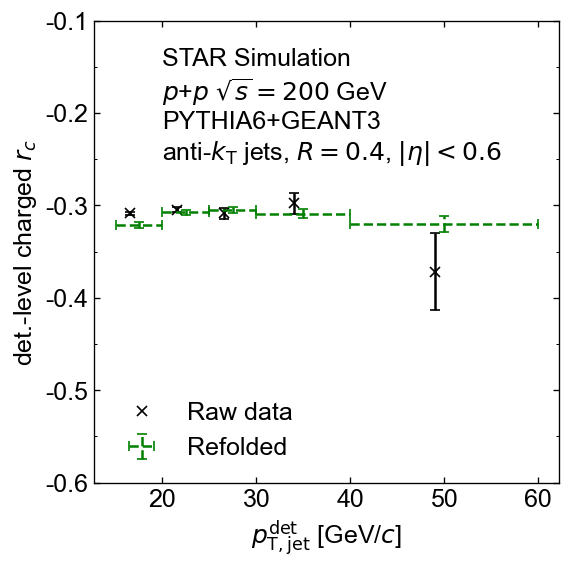

In [159]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([16.5, 21.5, 26.5, 34., 49], rc_data_array, yerr=rc_err_data_array, capsize=3, color='k', ls='none')
# plt.errorbar([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, yerr=rc_err_fakesubtracted_array, capsize=3, color='r', ls='none')
# plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, yerr=np.sqrt((np.asarray(rc_err_match_bs_vs_pt_array))**2+(np.asarray(rc_rwerr_match_bs_vs_pt_array))**2), capsize=3, color='olive', ls='none')
plt.plot([16.5, 21.5, 26.5, 34., 49], rc_data_array, color='k', ls='none', marker='x', label='Raw data')
# plt.plot([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
# plt.plot([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, color='olive', ls='none', marker='o', label='Fully corrected (after 2 steps)')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_refold_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_refold_array, capsize=3, color='g', ls='none', label='Refolded')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('det.-level charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.25, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')

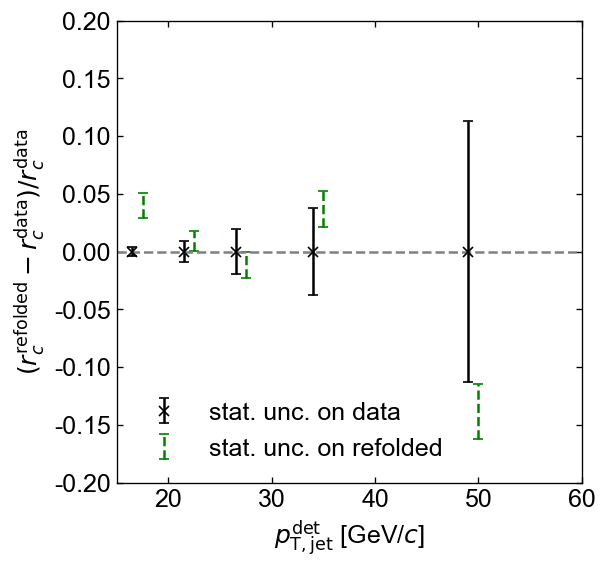

In [168]:
fig=plt.figure(figsize=(5,5))
# plt.errorbar([17.5, 22.5, 27.5, 35, 50], (np.asarray(rc_data_array)-np.asarray(rc_refold_array))/np.asarray(rc_refold_array), yerr=np.sqrt((np.asarray(rc_err_match_bs_vs_pt_array))**2+(np.asarray(rc_rwerr_match_bs_vs_pt_array))**2)/abs(np.asarray(rc2_truth_b_vs_pt_array)), capsize=3, color='olive', ls='none', label='stat. unc. on corrected')
#plt.plot([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, color='k', ls='none', marker='x', label='Raw')
#plt.plot([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
plt.errorbar([16.5, 21.5, 26.5, 34., 49], np.zeros(5), yerr=np.asarray(rc_err_data_array)/abs(np.asarray(rc_data_array)), color='k', ls='none', marker='x', capsize=3, label='stat. unc. on data')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], (np.asarray(rc_refold_array)-np.asarray(rc_data_array))/np.asarray(rc_data_array), yerr=np.asarray(rc_err_refold_array)/abs(np.asarray(rc_data_array)), capsize=3, color='g', ls='none', label='stat. unc. on refolded')
eb1[-1][0].set_linestyle('--')
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$(r_c^{\mathrm{refolded}}-r_c^{\mathrm{data}})/r_c^{\mathrm{data}}$')
plt.ylim(-0.2,0.2)
plt.xlim(15, 60)
plt.legend(loc='lower left', frameon=False)
#plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')

In [170]:
print("black errorbar size:", np.asarray(rc_err_data_array)/abs(np.asarray(rc_data_array)))
print("green errorbar size:", np.asarray(rc_err_refold_array)/abs(np.asarray(rc_data_array)))
print("green central marker:", (np.asarray(rc_refold_array)-np.asarray(rc_data_array))/np.asarray(rc_data_array))

black errorbar size: [0.00429017 0.00937784 0.01942826 0.03740495 0.11318943]
green errorbar size: [0.01097985 0.00885719 0.0114689  0.01529495 0.02407211]
green central marker: [ 0.03989532  0.0090424  -0.01163812  0.0368232  -0.13841833]


# check that the stat. unc. makes sense

In [58]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [60]:
eff_count,eff_count_err,x = calc_hist(df_data['pts'], bins=[15,20,25,30,40,60], weights=np.ones(df_data.shape[0]))
print("stat. unc. for data jets:", eff_count_err/eff_count)
eff_count,eff_count_err,x = calc_hist(df_allreco['pts'], bins=[15,20,25,30,40,60], weights=df_allreco['w'])
print("stat. unc. for embedding jets:", eff_count_err/eff_count)

stat. unc. for data jets: [0.00139285 0.00300241 0.00630717 0.01167934 0.04531433]
stat. unc. for embedding jets: [0.00282313 0.00238802 0.00325649 0.00407114 0.00881732]
